In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

np.random.seed(42)
tf.random.set_seed(42)

In [3]:
train_path = '../data/sales/train.csv'
test_path = '../data/sales/test.csv'

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

print(train_df.head())

Train shape: (1017209, 9)
Test shape: (41088, 8)
   Store  DayOfWeek        Date  Sales  Customers  Open  Promo StateHoliday  \
0      1          5  2015-07-31   5263        555     1      1            0   
1      2          5  2015-07-31   6064        625     1      1            0   
2      3          5  2015-07-31   8314        821     1      1            0   
3      4          5  2015-07-31  13995       1498     1      1            0   
4      5          5  2015-07-31   4822        559     1      1            0   

   SchoolHoliday  
0              1  
1              1  
2              1  
3              1  
4              1  


/tmp/ipykernel_10031/4284806047.py:4: DtypeWarning: Columns (7: StateHoliday) have mixed types. Specify dtype option on import or set low_memory=False.
  train_df = pd.read_csv(train_path)


In [8]:
date_col = 'Date' if 'Date' in train_df.columns else 'date'
train_df[date_col] = pd.to_datetime(train_df[date_col])

# 2. Sort values
train_df = train_df.sort_values(date_col)

ts_data = train_df.groupby(date_col)['Sales'].sum().reset_index()

ts_data.set_index(date_col, inplace=True)
ts_data.index = pd.to_datetime(ts_data.index)

ts_data = ts_data.resample('D').sum().fillna(0)

print(ts_data.head())

              Sales
Date               
2013-01-01    97235
2013-01-02  6949829
2013-01-03  6347820
2013-01-04  6638954
2013-01-05  5951593


/tmp/ipykernel_10031/1377706270.py:9: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  ts_data.set_index(date_col, inplace=True)


In [10]:
sales_col = 'Sales' if 'Sales' in ts_data.columns else 'sales'

scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(ts_data[[sales_col]])

def create_windows(data, look_back=30):
    X, y = [], []
    for i in range(look_back, len(data)):
        X.append(data[i-look_back:i, 0])
        y.append(data[i, 0])
    return np.array(X), np.array(y)

LOOK_BACK = 30
X, y = create_windows(scaled_data, look_back=LOOK_BACK)

X = np.reshape(X, (X.shape[0], X.shape[1], 1))

train_size = int(len(X) * 0.8)

X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")

X_train shape: (729, 30, 1), X_test shape: (183, 30, 1)


In [12]:
model = Sequential([
    LSTM(50, return_sequences=True, input_shape=(X_train.shape[1], 1)),
    Dropout(0.2),
    LSTM(50, return_sequences=False),
    Dropout(0.2),
    Dense(25),
    Dense(1)
])

model.compile(optimizer='adam', loss='mean_squared_error')

history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_test, y_test),
    verbose=1
)

Epoch 1/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 5s 47ms/step - loss: 0.0683 - val_loss: 0.0474
Epoch 2/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0433 - val_loss: 0.0452
Epoch 3/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0425 - val_loss: 0.0457
Epoch 4/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0434 - val_loss: 0.0454
Epoch 5/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0425 - val_loss: 0.0455
Epoch 6/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0418 - val_loss: 0.0453
Epoch 7/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0435 - val_loss: 0.0448
Epoch 8/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0420 - val_loss: 0.0450
Epoch 9/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0428 - val_loss: 0.0444
Epoch 10/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0428 - val_loss: 0.0440
Epoch 11/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0415 - val_loss: 0.0438
Epoch 12/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0

6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 67ms/step
Test MAE: 2336637.42
Test RMSE: 3218663.07


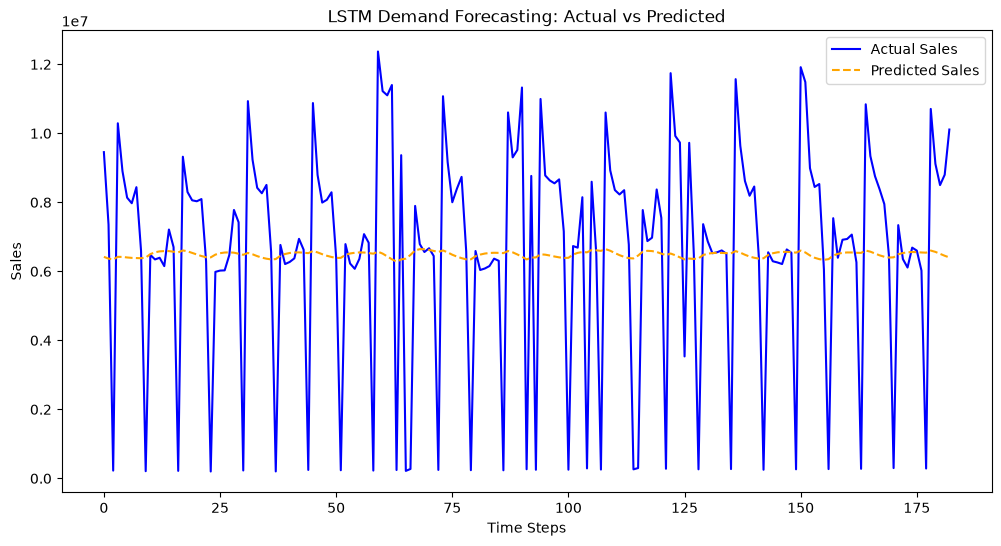

In [13]:
# Predict on test set
predictions = model.predict(X_test)

# Inverse transform to original scale
predictions_inv = scaler.inverse_transform(predictions)
y_test_inv = scaler.inverse_transform(y_test.reshape(-1, 1))

# Calculate metrics
mae = mean_absolute_error(y_test_inv, predictions_inv)
rmse = np.sqrt(mean_squared_error(y_test_inv, predictions_inv))

print(f"Test MAE: {mae:.2f}")
print(f"Test RMSE: {rmse:.2f}")

# Plot Predicted vs Actual
plt.figure(figsize=(12, 6))
plt.plot(y_test_inv, label='Actual Sales', color='blue')
plt.plot(predictions_inv, label='Predicted Sales', color='orange', linestyle='--')
plt.title('LSTM Demand Forecasting: Actual vs Predicted')
plt.xlabel('Time Steps')
plt.ylabel('Sales')
plt.legend()
plt.show()